# Data preparation for model comparison

Target: `final_grade_pct` (regression). Predictors are grouped as continuous, discrete, or categorical.

The order follows a leak-free pipeline: split first, then impute, encode, prune correlated predictors, and select with Lasso. Every fitted statistic comes from the training rows only.

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv('student_grade_ses_dataset.csv')
print(df.shape)

(12025, 29)


## Clean duplicate rows

Exact duplicate rows (25) are removed before the split, so the same record cannot appear in both training and test sets. Missing values are kept here and imputed after the split, using training-set statistics only.

In [2]:
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_missing = int(df.isna().any(axis=1).sum())
print(f'{n_raw} rows -> {len(df)} after removing duplicates; {n_missing} rows have at least one missing value (imputed after the split)')

12025 rows -> 12000 after removing duplicates; 3215 rows have at least one missing value (imputed after the split)


## Target and predictors

`grade_class` and `at_risk_flag` are excluded because both are computed from the target. `student_id` becomes the row index, and `survey_date` is excluded because all survey dates fall in March to May 2025.

In [3]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transformed
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',
                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',
                 'parental_involvement_score']

# Text labels
CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',
                    'father_education_level', 'mother_education_level', 'father_occupation',
                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [4]:
# student_id is unique after de-duplication, so it can serve as the row index
df = df.set_index('student_id')
assert df.index.is_unique

X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

X: (12000, 24)  Y: (12000,)


## Train/test split

85% of rows go to training and 15% to test. Stratifying on `grade_class` keeps the rare F and A grades in both sets. The test set is set aside, and it is used only once, at the end.

In [5]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.15
SEED = 42

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED)

print('train:', X_train.shape, ' test:', X_test.shape)
print('test grade_class counts:', df.loc[X_test.index, 'grade_class'].value_counts().to_dict())

train: (10200, 24)  test: (1800, 24)
test grade_class counts: {'C': 922, 'D': 411, 'B': 403, 'F': 33, 'A': 31}


## Missing value imputation

Numeric predictors (including 0/1 flags and discrete scores) get the training median, and categorical predictors get the training mode. Both statistics are computed on the training rows only and then applied to the test rows. This keeps every row, instead of dropping the 27% that have at least one gap.

In [6]:
print('missing before imputation (train):', X_train.isna().sum()[lambda s: s > 0].to_dict())

medians = X_train[NUMERIC_COLS].median()
modes = X_train[CATEGORICAL_COLS].mode().iloc[0]

for X_part in (X_train, X_test):
    X_part[NUMERIC_COLS] = X_part[NUMERIC_COLS].fillna(medians)
    X_part[CATEGORICAL_COLS] = X_part[CATEGORICAL_COLS].fillna(modes)

assert X_train.notna().all().all() and X_test.notna().all().all()
print('train:', X_train.shape, ' test:', X_test.shape)

missing before imputation (train): {'distance_to_school_km': 208, 'attendance_rate_pct': 259, 'previous_year_grade_pct': 299, 'log_income': 609, 'has_internet_access': 162, 'father_education_level': 354, 'mother_education_level': 301, 'father_occupation': 412, 'mother_occupation': 521}
train: (10200, 24)  test: (1800, 24)


## One-hot encoding

Each categorical predictor becomes 0/1 columns, one per level. The first training level of each variable is dropped as the reference, which avoids perfect collinearity with the intercept in linear models. The encoder is fit on the training rows only. Test rows are aligned to the training columns, and a level never seen in training is ignored.

In [7]:
ref_cols = [f'{c}_{sorted(X_train[c].unique())[0]}' for c in CATEGORICAL_COLS]

X_train = pd.get_dummies(X_train, columns=CATEGORICAL_COLS, dtype=float).drop(columns=ref_cols)
X_test = pd.get_dummies(X_test, columns=CATEGORICAL_COLS, dtype=float).reindex(columns=X_train.columns, fill_value=0.0)
print('encoded train:', X_train.shape, ' encoded test:', X_test.shape)

encoded train: (10200, 54)  encoded test: (1800, 54)


## Correlation-based predictor pruning

Among the numeric predictors, any pair with |Pearson r| above 0.8 on the training rows is treated as collinear. For each such pair, the predictor less associated with the target is dropped. This runs before Lasso so that correlated predictors do not produce unstable coefficient shrinkage. Dummy columns are not screened.

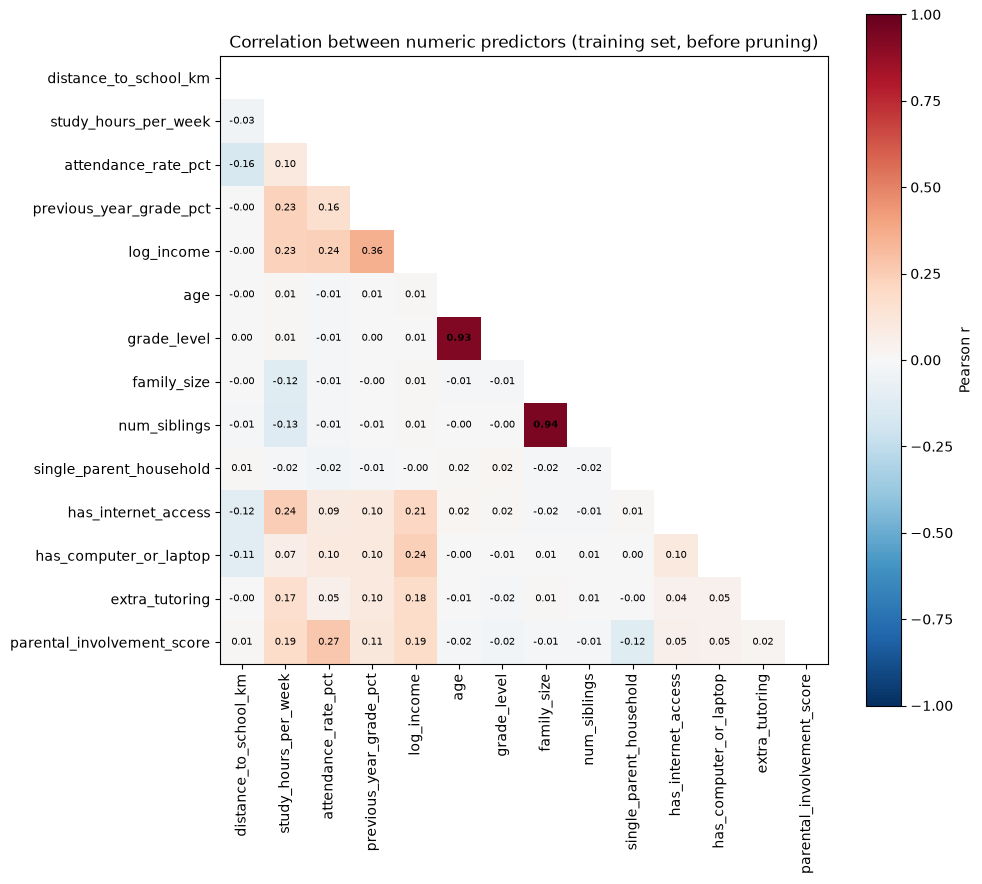

In [8]:
import matplotlib.pyplot as plt

CORR_THRESHOLD = 0.8

num_corr_all = X_train[NUMERIC_COLS].corr()
lower = num_corr_all.mask(np.triu(np.ones_like(num_corr_all, dtype=bool)))

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(lower.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_COLS)), NUMERIC_COLS, rotation=90)
ax.set_yticks(range(len(NUMERIC_COLS)), NUMERIC_COLS)
for row in range(len(NUMERIC_COLS)):
    for col in range(row):
        r = num_corr_all.iloc[row, col]
        ax.text(col, row, f'{r:.2f}', ha='center', va='center', fontsize=7,
                fontweight='bold' if abs(r) > CORR_THRESHOLD else 'normal')
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_title('Correlation between numeric predictors (training set, before pruning)')
plt.tight_layout()
plt.show()

In [9]:
def source_variable(col):
    # Maps a one-hot column back to its raw predictor name
    for raw in PREDICTOR_COLS:
        if col == raw or col.startswith(raw + '_'):
            return raw
    return col


num_corr = X_train[NUMERIC_COLS].corr()
assoc_with_target = X_train[NUMERIC_COLS].corrwith(Y_train).abs()
high_pairs = [(a, b) for i, a in enumerate(NUMERIC_COLS) for b in NUMERIC_COLS[:i]
              if abs(num_corr.loc[a, b]) > CORR_THRESHOLD]

CORR_DROP = set()
for a, b in high_pairs:
    if a not in CORR_DROP and b not in CORR_DROP:
        CORR_DROP.add(a if assoc_with_target[a] < assoc_with_target[b] else b)

print('pairs above threshold:', high_pairs)
print('dropped for correlation:', sorted(CORR_DROP))

PRUNED_PREDICTORS = [p for p in PREDICTOR_COLS if p not in CORR_DROP]
PRUNED_COLS = [c for c in X_train.columns if source_variable(c) in PRUNED_PREDICTORS]
X_train = X_train[PRUNED_COLS]
X_test = X_test[PRUNED_COLS]
print(f'pruned: {len(PRUNED_PREDICTORS)} predictors ({len(PRUNED_COLS)} encoded columns)')

pairs above threshold: [('grade_level', 'age'), ('num_siblings', 'family_size')]
dropped for correlation: ['grade_level', 'num_siblings']
pruned: 22 predictors (52 encoded columns)


## Predictor selection (Lasso)

A single Lasso fit on the pruned training set shows which predictors it switches off. Numeric predictors are standardised inside the pipeline. The penalty is the largest one within one standard error of the best 10-fold CV score on the training rows. A predictor is kept if any of its encoded columns has a non-zero coefficient. The bar chart below shows every encoded coefficient; grey bars are the ones Lasso switched off. The test set is not used here.

CV-selected alpha: 0.0131  CV RMSE: 9.616
alpha at 1-SE: 0.1366
                            max |coef|        status
previous_year_grade_pct         4.8854          kept
log_income                      1.5396          kept
scholarship_status              1.1605          kept
study_hours_per_week            0.7482          kept
has_internet_access             0.6994          kept
has_computer_or_laptop          0.6499          kept
attendance_rate_pct             0.4243          kept
extra_tutoring                  0.3676          kept
mother_education_level          0.3653          kept
family_size                     0.2680          kept
single_parent_household         0.2012          kept
parental_involvement_score      0.0000  switched off
school_type                     0.0000  switched off
residence_type                  0.0000  switched off
distance_to_school_km           0.0000  switched off
family_income_bracket           0.0000  switched off
mother_occupation               0.0

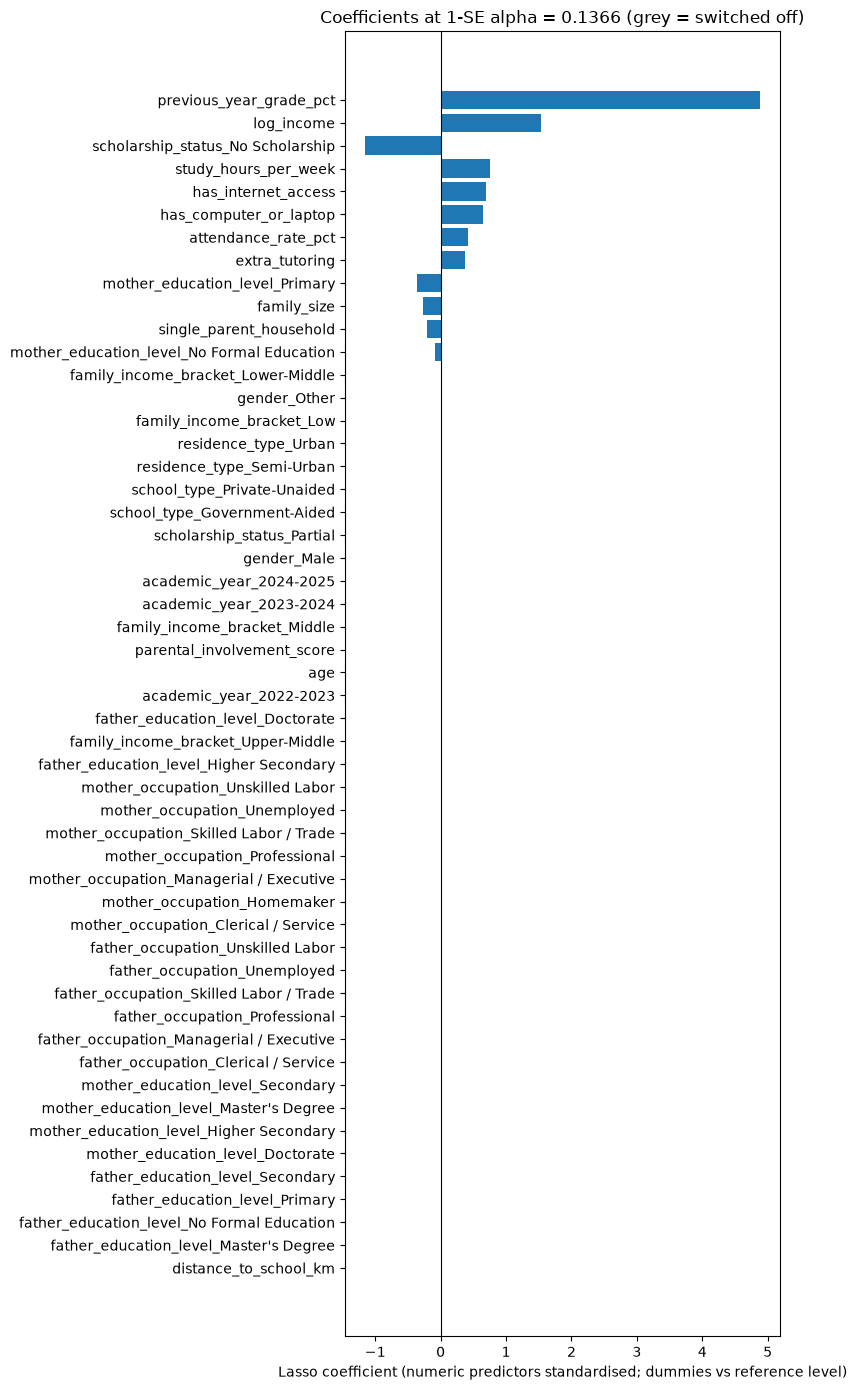

In [10]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_SPLITS = 10
ALPHA_GRID = np.logspace(-4, 1, 60)
ALL_COLS = list(X_train.columns)


def make_pipe(cols):
    # Continuous and discrete columns (including 0/1 flags) are scaled. One-hot dummy columns pass through unchanged.
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), Lasso(max_iter=20000))


def one_se_alpha(search):
    # Largest alpha whose CV error is within one standard error of the best
    mean_rmse = -search.cv_results_['mean_test_score']
    se = search.cv_results_['std_test_score'] / np.sqrt(N_SPLITS)
    best = np.argmin(mean_rmse)
    return ALPHA_GRID[mean_rmse <= mean_rmse[best] + se[best]].max()


folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train))
search = GridSearchCV(make_pipe(ALL_COLS), {'lasso__alpha': ALPHA_GRID}, cv=folds,
                      scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, Y_train)
ALPHA_1SE = one_se_alpha(search)
print(f'CV-selected alpha: {search.best_params_["lasso__alpha"]:.4f}  CV RMSE: {-search.best_score_:.3f}')
print(f'alpha at 1-SE: {ALPHA_1SE:.4f}')

lasso_fit = make_pipe(ALL_COLS).set_params(lasso__alpha=ALPHA_1SE).fit(X_train, Y_train)
lasso_coef = pd.Series(lasso_fit[-1].coef_, index=lasso_fit[:-1].get_feature_names_out())
predictor_of = lasso_coef.index.map(source_variable)

kept_levels = lasso_coef[lasso_coef != 0].index.map(source_variable)
SELECTED_PREDICTORS = [p for p in PRUNED_PREDICTORS if p in set(kept_levels)]
FINAL_COLS = [c for c in ALL_COLS if source_variable(c) in SELECTED_PREDICTORS]

summary = lasso_coef.abs().groupby(predictor_of).max().rename('max |coef|').to_frame()
summary['status'] = np.where(summary.index.isin(SELECTED_PREDICTORS), 'kept', 'switched off')
print(summary.sort_values('max |coef|', ascending=False).round(4).to_string())
print(f'kept {len(SELECTED_PREDICTORS)} of {len(PRUNED_PREDICTORS)} pruned predictors ({len(FINAL_COLS)} encoded columns)')

X_train_final = X_train[FINAL_COLS]
X_test_final = X_test[FINAL_COLS]

order = lasso_coef.abs().sort_values().index
bar_colors = ['tab:blue' if lasso_coef[c] != 0 else 'lightgray' for c in order]

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(order, lasso_coef[order], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Lasso coefficient (numeric predictors standardised; dummies vs reference level)')
ax.set_title(f'Coefficients at 1-SE alpha = {ALPHA_1SE:.4f} (grey = switched off)')
plt.tight_layout()
plt.show()

## Save the prepared data

The model notebooks (`Project-Linear.ipynb`, `Project-Trees.ipynb`) load these files instead of repeating the preparation. Only the kept predictors are saved, together with the column groupings they need to scale numeric columns. Run this notebook first.

In [11]:
import json
from pathlib import Path

DATA_DIR = Path('prepared_data')
DATA_DIR.mkdir(exist_ok=True)

X_train_final.to_csv(DATA_DIR / 'X_train.csv')
X_test_final.to_csv(DATA_DIR / 'X_test.csv')
Y_train.to_csv(DATA_DIR / 'Y_train.csv')
Y_test.to_csv(DATA_DIR / 'Y_test.csv')

meta = {
    'seed': SEED,
    'n_splits': N_SPLITS,
    'target': TARGET_COL,
    'predictor_cols': PREDICTOR_COLS,
    'numeric_cols': NUMERIC_COLS,
    'categorical_cols': CATEGORICAL_COLS,
    'selected_predictors': SELECTED_PREDICTORS,
}
with open(DATA_DIR / 'meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print(f'saved to {DATA_DIR}/: train {X_train_final.shape}, test {X_test_final.shape}')

saved to prepared_data/: train (10200, 17), test (1800, 17)


## Summary of preparation

- **Lasso switches off 11 of 22 pruned predictors.** The kept predictors are previous-year grade, log income, scholarship status, study hours, internet access, computer access, attendance, extra tutoring, mother's education, family size, and single-parent household. The switched-off ones are parental involvement, school type, residence type, distance to school, family income bracket, mother's occupation, age, gender, father's occupation, father's education, and academic year. Their coefficients are exactly zero in the coefficient chart.
- **Caveat.** Imputation statistics, correlation pruning, and the Lasso fit are computed once on the full training set, before the models' outer CV. The CV scores in the model notebooks are therefore somewhat optimistic. The test set is untouched by every step here.